# Manpower July 2024: incidents per unit

OPD unit status log from the old CAD, July 2024. Each row is one status change for one unit (call sign). This notebook builds three tables:

| Table | One row per | Holds |
|---|---|---|
| `unit_inc` | unit x incident | minutes en route, on scene, on follow-up (transport, hospital, jail), on detail |
| `incidents` | incident | units, duration, unit-hours; priority, source and type from CAD |
| `shifts` | unit log-on to log-off | shift start, end, hours |

It then counts the incidents each patrol car takes per shift and measures how long incidents take.

**Date scope:** complete days only, 1-29 July 2024. The data ends at 29 July because OPD switched to a new CAD system on 30 July, and this log comes from the old one. 18 and 19 July are dropped entirely (CAD outage night).

In [1]:
import numpy as np
import pandas as pd
from box_utils import BOX_ROOT

MANPOWER_DIR = BOX_ROOT / "2026.09.29 one_percent"
DATA = BOX_ROOT / "OPD & TAN - Core Workspace" / "OPD - Oakland Police Dept" / "Data" / "Our Data"

In [2]:
# check if 1% july 2024 portion and july 2024 data are the same -> they are 
july2024 = pd.read_csv(MANPOWER_DIR / "Man_Power_2024_July.csv", low_memory=False)
one_pct_2024 = pd.read_csv(MANPOWER_DIR / "Man_Power_2024_1_percent.csv", low_memory=False)

one_pct_2024_time = pd.to_datetime(one_pct_2024["Manpower_Record_Time"], format="%Y %b %d %I:%M:%S %p")
one_pct_2024_july = one_pct_2024[one_pct_2024_time.dt.month == 7]

print("July 2024:     ", july2024.shape)
print("2024 1%:       ", one_pct_2024.shape)
print("2024 1%, July: ", one_pct_2024_july.shape)

a = july2024.reset_index(drop=True)
b = one_pct_2024_july.reset_index(drop=True)
print("identical as read:", a.equals(b))

# the two files write Manpower_Record_Time differently, and Unit_Shift is read as text in the 1% file
for d in (a, b):
    d["Manpower_Record_Time"] = pd.to_datetime(d["Manpower_Record_Time"], format="mixed")
    d["Unit_Shift"] = pd.to_numeric(d["Unit_Shift"])

print("same columns:         ", list(a.columns) == list(b.columns))
print("same rows (by PK):    ", set(a["Manpower_PK"]) == set(b["Manpower_PK"]))
print("same rows, same order:", a["Manpower_PK"].equals(b["Manpower_PK"]))
print("identical after time and Unit_Shift fixed:", a.equals(b))

July 2024:      (188070, 18)
2024 1%:        (1361377, 18)
2024 1%, July:  (188070, 18)
identical as read: False
same columns:          True
same rows (by PK):     True
same rows, same order: True
identical after time and Unit_Shift fixed: True


In [13]:
# New dataset: Man_Power_2024_July_matched.csv plus code meanings and Unit_ID parts
july2024_matched = pd.read_csv(DATA / "Man_Power_2024_July_matched.csv", low_memory=False)

# 1. Fix types: comma text to numbers, time text to datetime
for col in ["Manpower_PK", "Incident_FK", "Seconds_At_Status"]:
    july2024_matched[col] = pd.to_numeric(july2024_matched[col].str.replace(",", "")).astype("Int64")
july2024_matched["Manpower_Record_Time"] = pd.to_datetime(july2024_matched["Manpower_Record_Time"])

# 2. Sort each unit's rows in time order (PK breaks ties within the same second)
july2024_matched = july2024_matched.sort_values(["Unit_ID", "Manpower_Record_Time", "Manpower_PK"]).reset_index(drop=True)

# 3. Date scope: complete days only, 1-29 Jul 2024 (new CAD from 30 Jul), with 18-19 Jul dropped entirely (CAD outage night)
date = july2024_matched["Manpower_Record_Time"].dt.normalize()
in_scope = date.between("2024-07-01", "2024-07-29") & ~date.isin(pd.to_datetime(["2024-07-18", "2024-07-19"]))
july2024_matched = july2024_matched[in_scope].reset_index(drop=True)

# 4. Meaning of each Code, and the general category it falls under
CODE_MEANING = {
    # unit status (US command + 2-letter status)
    "USER": ("en route",                       "en route to call"),
    "USDS": ("dispatched at shift start",      "en route to call"),
    "USOS": ("on scene",                       "on scene"),
    "USOP": ("on scene, primary unit",         "on scene"),
    "USLC": ("on scene, location changed",     "on scene"),
    "USCI": ("continuing investigation",       "on scene"),
    "USAW": ("brief status change",            "on scene"),
    "USOV": ("officer-initiated activity",     "officer-initiated"),
    "USTS": ("traffic stop",                   "officer-initiated"),
    "USAV": ("available",                      "available"),
    "USTM": ("transporting a male",            "transporting a person"),
    "USTF": ("transporting a female",          "transporting a person"),
    "USPT": ("transporting a prisoner",        "transporting a person"),
    "USTC": ("transport complete",             "transporting a person"),
    "USEH": ("en route to hospital",           "en route to facility"),
    "USEP": ("en route to police HQ",          "en route to facility"),
    "USES": ("en route to Santa Rita Jail",    "en route to facility"),
    "USEJ": ("en route to jail for booking",   "en route to facility"),
    "USJE": ("en route to juvenile hall",      "en route to facility"),
    "USEY": ("en route to Youth Services",     "en route to facility"),
    "USEC": ("en route to CID",                "en route to facility"),
    "USEE": ("en route to evidence/tech",      "en route to facility"),
    "USAH": ("at hospital",                    "at facility"),
    "USAP": ("at police HQ",                   "at facility"),
    "USAS": ("at Santa Rita Jail",             "at facility"),
    "USAJ": ("at jail for booking",            "at facility"),
    "USJH": ("at juvenile hall",               "at facility"),
    "USAY": ("at Youth Services",              "at facility"),
    "USAC": ("at CID",                         "at facility"),
    "USCT": ("at court",                       "at facility"),
    "USAE": ("at evidence/tech",               "at facility"),
    "USAA": ("at airport",                     "at facility"),
    "USSA": ("special assignment",             "special assignment"),
    "USHG": ("hospital guard",                 "special assignment"),
    "USDP": ("directed patrol",                "special assignment"),
    "USIC": ("incident command",               "special assignment"),
    "USCE": ("community engagement",           "special assignment"),
    "USAT": ("at station after log-on",        "out of service"),
    "USCY": ("at corp yard",                   "out of service"),
    # other commands
    "UO":   ("log on",                         "log on"),
    "UF":   ("log off",                        "log off"),
    "FR":   ("freed from incident",            "assignment change"),
    "UR":   ("reassigned to another incident", "assignment change"),
    "UX":   ("units swap assignments",         "assignment change"),
    "US":   ("moved to another area",          "assignment change"),
    "UU":   ("status update",                  "status update"),
    "D":    ("disposition added",              "disposition"),
    "CU":   ("crew size",                      "unit setup"),
    "CA":   ("unit capabilities",              "unit setup"),
    "O1":   ("officer 1 name and ID",          "unit setup"),
    "O2":   ("officer 2 name and ID",          "unit setup"),
    "O3":   ("officer 3 name and ID",          "unit setup"),
    "O4":   ("officer 4 name and ID",          "unit setup"),
    "R1":   ("officer 1 radio",                "unit setup"),
    "R2":   ("officer 2 radio",                "unit setup"),
    "R3":   ("officer 3 radio",                "unit setup"),
    "R4":   ("officer 4 radio",                "unit setup"),
    "S1":   ("officer 1 skill",                "unit setup"),
    "S2":   ("officer 2 skill",                "unit setup"),
    "S3":   ("officer 3 skill",                "unit setup"),
    "S4":   ("officer 4 skill",                "unit setup"),
    "RD":   ("rider added",                    "unit setup"),
    "VR":   ("vehicle radio",                  "unit setup"),
    "VI":   ("vehicle ID updated",             "unit setup"),
    "DT":   ("duty type",                      "unit setup"),
    "BT":   ("beat assigned",                  "unit setup"),
    "LO":   ("location updated",               "location update"),
    "PN":   ("plate number entered",           "plate entry"),
    "PNOS": ("plate number entered",           "plate entry"),
    "PNOV": ("plate number entered",           "plate entry"),
    "PNTS": ("plate number entered",           "plate entry"),
    "PNAP": ("plate number entered",           "plate entry"),
    "CM":   ("comment",                        "note"),
    "ON":   ("officer note",                   "note"),
    "EM":   ("emergency button pressed",       "emergency"),
    "IM":   ("emergency reset",                "emergency"),
}
july2024_matched["code_meaning"] = july2024_matched["Code"].map(lambda c: CODE_MEANING[c][0])
july2024_matched["code_category"] = july2024_matched["Code"].map(lambda c: CODE_MEANING[c][1])

# UO on a roster row (Record_Type 1) is CAD's overdue-timer reset, not a log on
uo_reset = (july2024_matched["Code"] == "UO") & (july2024_matched["Record_Type"] == 1)
july2024_matched.loc[uo_reset, "code_meaning"] = "overdue-timer reset"
july2024_matched.loc[uo_reset, "code_category"] = "timer reset"

# 5. Meaning of Record_Type
RECORD_TYPE_MEANING = {
    1: "roster/setup",
    2: "status change",
    4: "disposition",
}
july2024_matched["record_type_meaning"] = july2024_matched["Record_Type"].map(RECORD_TYPE_MEANING)

# 6. Split call signs (e.g. 3L08): unit type from the letter; shift and beat for patrol beat cars only
UNIT_TYPE = {
    "L": "line patrol, 1 officer",
    "A": "line patrol, 2 officers",
    "J": "2-officer patrol-like car",
    "S": "2-officer special unit",
    "T": "traffic",
    "X": "special assignment unit",
    "F": "foot patrol unit",
    "C": "stolen vehicle / animal unit",
    "D": "detective",
    "M": "motorcycle",
    "K": "K-9",
    "B": "unknown",
    "V": "unknown",
}
SHIFT = {
    "1": "day",
    "2": "evening",
    "3": "night",
}
SHIFT_HOURS = {  # start depends on the Patrol Area (OPD memo, 1 Jul 2023)
    "1": "6/7am-4/5pm",
    "2": "2pm-2am",
    "3": "9/10pm-7/8am",
}
july2024_matched["is_patrol"] = july2024_matched["Unit_ID"].str.match(r"^[123][LA](0[1-9]|[12]\d|3[0-5])$")
july2024_matched["unit_type"] = july2024_matched["Unit_ID"].str.extract(r"^\d+([A-Z])\d+$")[0].map(UNIT_TYPE)
parts = july2024_matched["Unit_ID"].where(july2024_matched["is_patrol"]).str.extract(r"^(\d)[LA](\d\d)$")
july2024_matched["shift"] = parts[0].map(SHIFT)
july2024_matched["shift_hours"] = parts[0].map(SHIFT_HOURS)
july2024_matched["beat"] = parts[1]

# 7. Put each new column right after the column it comes from
NEW_AFTER = {
    "Code":        ["code_meaning", "code_category"],
    "Record_Type": ["record_type_meaning"],
    "Unit_ID":     ["is_patrol", "unit_type", "shift", "shift_hours", "beat"],
}
new_cols = [col for cols in NEW_AFTER.values() for col in cols]
order = []
for col in july2024_matched.columns:
    if col not in new_cols:
        order += [col] + NEW_AFTER.get(col, [])
july2024_matched = july2024_matched[order]

print(july2024_matched.shape)

(174975, 29)


In [19]:
july2024_patrol = july2024_matched[july2024_matched["is_patrol"]]
july2024_patrol.head(3)

,Unnamed: 0,Manpower_PK,Incident_FK,Address,Area,Audit_Type,Beat,Code,code_meaning,code_category,...,shift,shift_hours,beat,Unit_Shift,Vehicle,Table_Type,Combined_Text_No_Time,matched_incident_number,incident_priority,match_method
7277,1257648,97919811,<NA>,NaN,NaN,US,NaN,RD,rider added,unit setup,...,day,6/7am-4/5pm,02,NaN,NaN,ManPower,No unit records associated to this incident,NaN,NaN,NaN
7278,995649,97919812,<NA>,NaN,NaN,US,NaN,R1,officer 1 radio,unit setup,...,day,6/7am-4/5pm,02,NaN,NaN,ManPower,No unit records associated to this incident,NaN,NaN,NaN
7279,1257649,97919813,<NA>,NaN,NaN,US,NaN,DT,duty type,unit setup,...,day,6/7am-4/5pm,02,NaN,NaN,ManPower,No unit records associated to this incident,NaN,NaN,NaN


In [ ]:
# 8. Save as a new CSV next to the matched file
july2024_matched.to_csv(DATA / "Man_Power_2024_July_matched_codes.csv", index=False)

# Plots of Counts

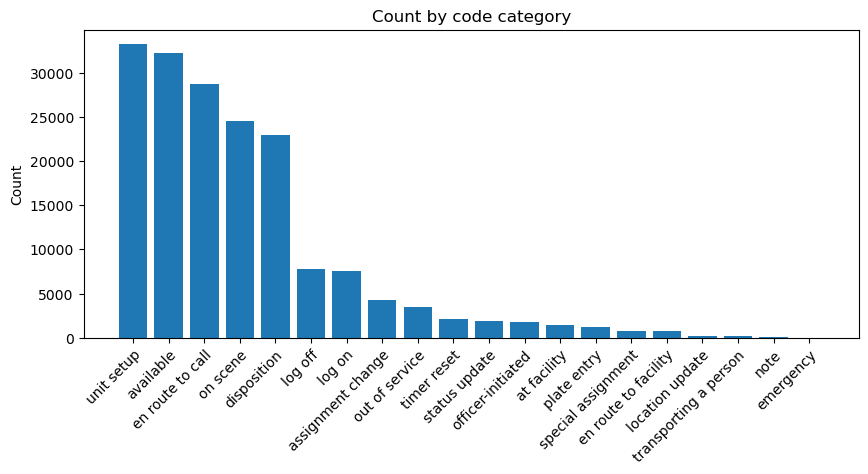

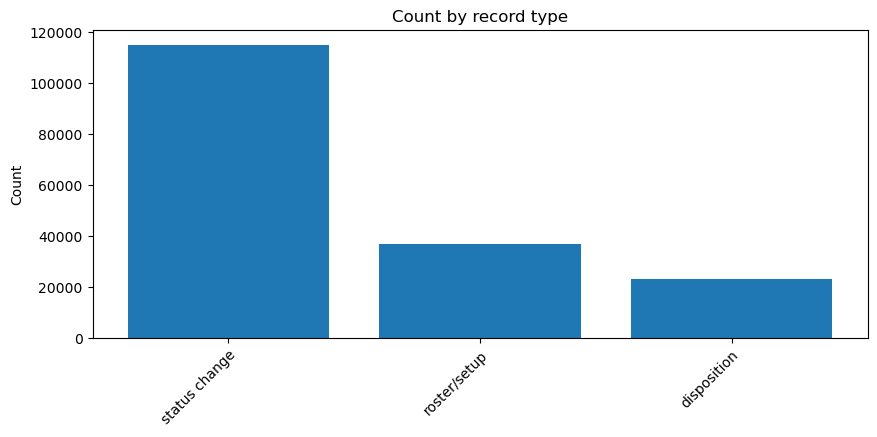

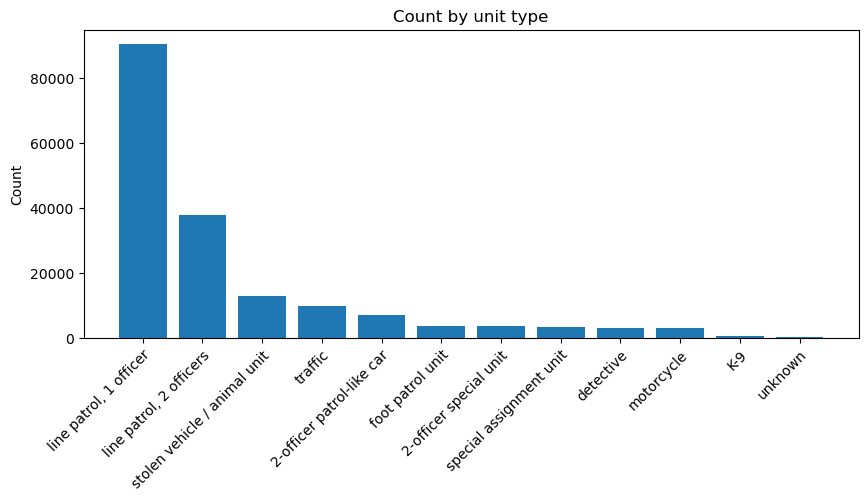

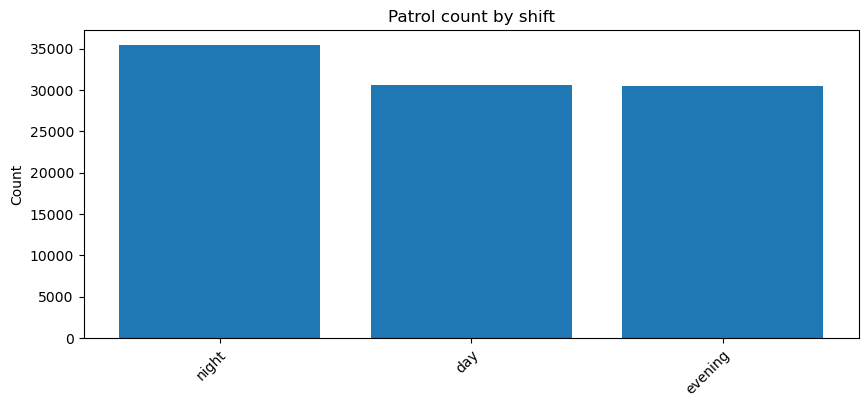

In [17]:
import matplotlib.pyplot as plt

# Bar chart of counts for one column, largest on the left
def bar_counts(data, col, title):
    counts = data[col].value_counts()
    plt.figure(figsize=(10, 4))
    plt.bar(counts.index.astype(str), counts.values)
    plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
    plt.title(title)
    plt.ylabel("Count")
    plt.show()

# log entries in each code category (what units were doing or recording)
bar_counts(july2024_matched, "code_category", "Count by code category")

# log entries by record type: status changes, roster/setup lines, dispositions
bar_counts(july2024_matched, "record_type_meaning", "Count by record type")

# log entries by unit type (the letter in the call sign)
bar_counts(july2024_matched, "unit_type", "Count by unit type")

# log entries from patrol beat cars only, by shift
bar_counts(july2024_patrol, "shift", "Patrol count by shift")